# Notebook 5 – Bivariate Analysis
**File:** `05_Bivariate_Analysis.ipynb`

## Objective
Study relationships between two variables. Association does not, by itself, establish causation. Examples use Telco Customer Churn.

## Setup and load data

This notebook uses the IBM Telco Customer Churn dataset. Put `WA_Fn-UseC_-Telco-Customer-Churn.csv` beside this notebook, or change `DATA_PATH` below.

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
sns.set_theme(style="whitegrid")

DATA_PATH = Path("WA_Fn-UseC_-Telco-Customer-Churn.csv")
DATA_PATH = Path( r"C:\Users\ramki\sprint_4\dataset\WA_Fn-UseC_-Telco-Customer-Churn.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError(f"CSV not found at {DATA_PATH.resolve()}. Update DATA_PATH.")
df = pd.read_csv(DATA_PATH)
if "TotalCharges" in df:
    df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Shape:", df.shape)
display(df.head())

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 1. Identify variable types
Topics: numerical vs numerical, numerical vs categorical, and categorical vs categorical. If your dataset uses Age/Salary, Income/Spending, Department/Salary, or Product Category/Sales, substitute those columns for the Telco examples.

In [7]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
numeric_cols = [c for c in numeric_cols if c.lower() not in {"customerid", "customer_id", "id"}]
categorical_cols = df.select_dtypes(include=["object","str", "category", "bool"]).columns.tolist()
print("Numerical:", numeric_cols)
print("Categorical:", categorical_cols)

Numerical: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical: ['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'Churn']


## 2. Numerical vs numerical: scatter plot and correlation
A scatter plot shows trends, clusters, and outliers. Pearson correlation measures linear association from -1 to +1; Spearman correlation measures monotonic association. Neither proves causality.

**Example:** `tenure` vs `MonthlyCharges`.

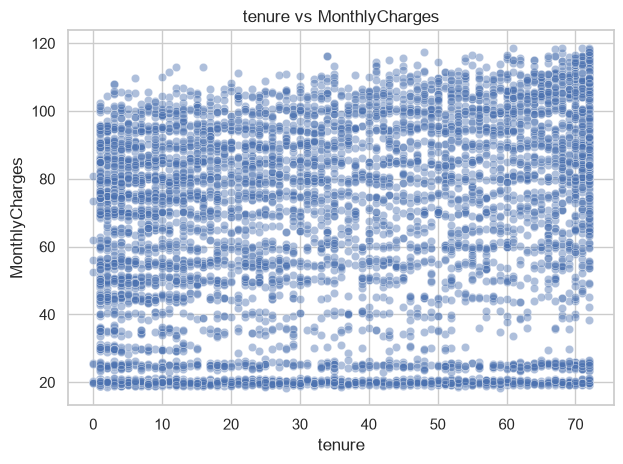

Pearson: 0.248
Spearman: 0.276


In [8]:
x_col, y_col = "tenure", "MonthlyCharges"
if {x_col, y_col}.issubset(df.columns):
    pair = df[[x_col, y_col]].apply(pd.to_numeric, errors="coerce").dropna()
    sns.scatterplot(data=pair, x=x_col, y=y_col, alpha=.45)
    plt.title(f"{x_col} vs {y_col}"); plt.tight_layout(); plt.show()
    print("Pearson:", round(pair[x_col].corr(pair[y_col]), 3))
    print("Spearman:", round(pair[x_col].corr(pair[y_col], method="spearman"), 3))
else:
    print("Choose two columns from numeric_cols.")

### Output explanation
Positive correlation means the variables tend to increase together; negative means one tends to decrease as the other increases. Near-zero Pearson correlation means little linear association, not necessarily no relationship. Check the plot for nonlinear patterns.

## 3. Numerical vs categorical: box plot and violin plot
Compare the distribution of a numeric feature across groups. A box plot highlights median and spread; a violin plot also shows a smoothed density.

**Example:** `MonthlyCharges` by `Contract`.

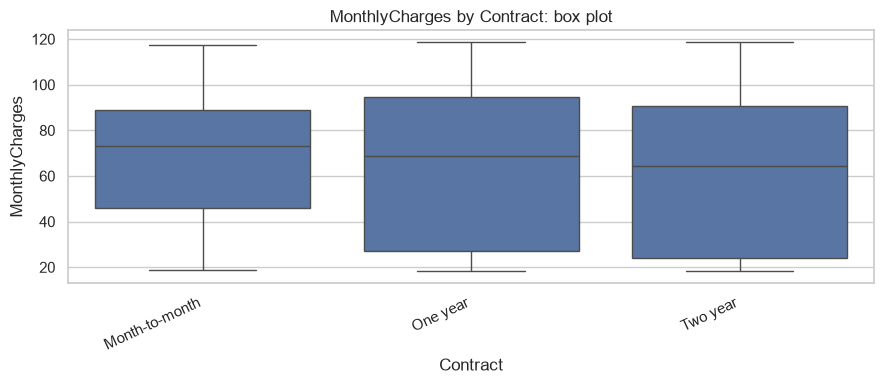

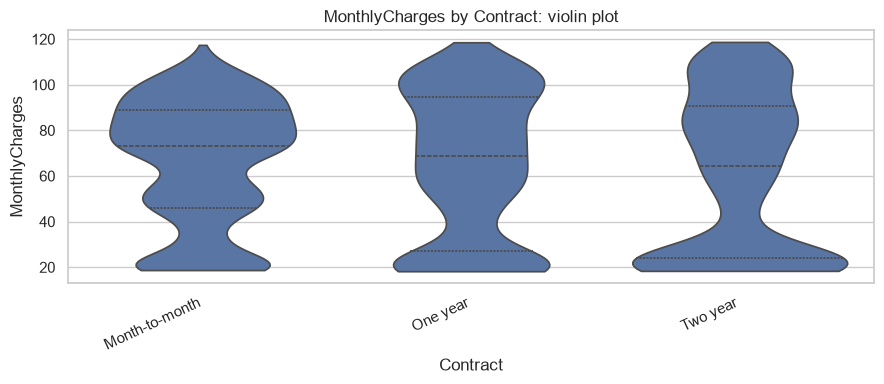

,count,mean,median,std
Contract,,,,
Month-to-month,3875,66.398,73.25,26.927
One year,1473,65.049,68.75,31.841
Two year,1695,60.770,64.35,34.679


In [9]:
num_col, cat_col = "MonthlyCharges", "Contract"
if {num_col, cat_col}.issubset(df.columns):
    p = df[[num_col, cat_col]].copy()
    p[num_col] = pd.to_numeric(p[num_col], errors="coerce")
    p = p.dropna()
    plt.figure(figsize=(9,4)); sns.boxplot(data=p, x=cat_col, y=num_col)
    plt.title(f"{num_col} by {cat_col}: box plot"); plt.xticks(rotation=25, ha="right")
    plt.tight_layout(); plt.show()
    plt.figure(figsize=(9,4)); sns.violinplot(data=p, x=cat_col, y=num_col, inner="quartile", cut=0)
    plt.title(f"{num_col} by {cat_col}: violin plot"); plt.xticks(rotation=25, ha="right")
    plt.tight_layout(); plt.show()
    display(p.groupby(cat_col)[num_col].agg(["count", "mean", "median", "std"]).round(3))
else:
    print("Choose one numerical and one categorical column.")

### Output explanation
Compare medians, interquartile ranges, overlap, and sample sizes. Group differences may indicate an association, but other variables may explain some of the pattern.

## 4. Categorical vs categorical: cross-tabulation and grouped bar chart
Cross-tabulation counts category combinations. Row-normalized percentages make the composition of each group comparable.

**Example:** `Contract` vs `Churn`.

Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1307,166
Two year,1647,48


Row percentages:


Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


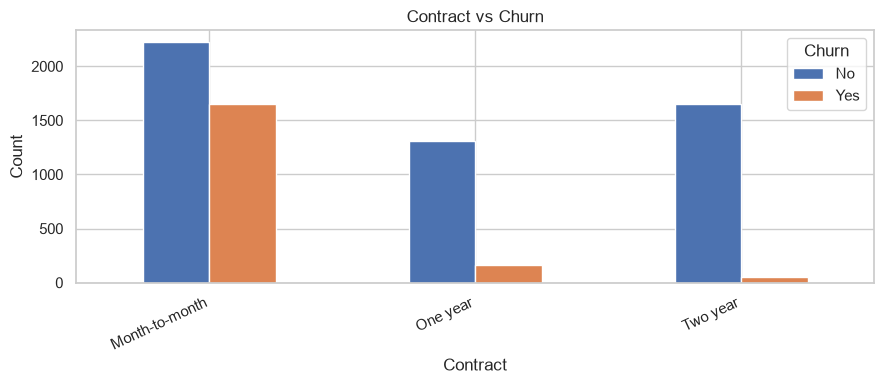

In [10]:
a, b = "Contract", "Churn"
if {a, b}.issubset(df.columns):
    ct = pd.crosstab(df[a], df[b])
    display(ct)
    print("Row percentages:")
    display((pd.crosstab(df[a], df[b], normalize="index") * 100).round(2))
    ct.plot(kind="bar", figsize=(9,4))
    plt.title(f"{a} vs {b}"); plt.ylabel("Count"); plt.xticks(rotation=25, ha="right")
    plt.tight_layout(); plt.show()
else:
    print("Choose two categorical columns.")

### Output explanation
Compare percentages rather than counts alone if groups differ in size. A difference in churn proportions across contract categories is an association to investigate, not proof of causation.

## 5. Reusable pair-analysis helper
Change the column names in the examples to analyze other pairs.

Numerical vs numerical; Pearson: 0.2478998562861499


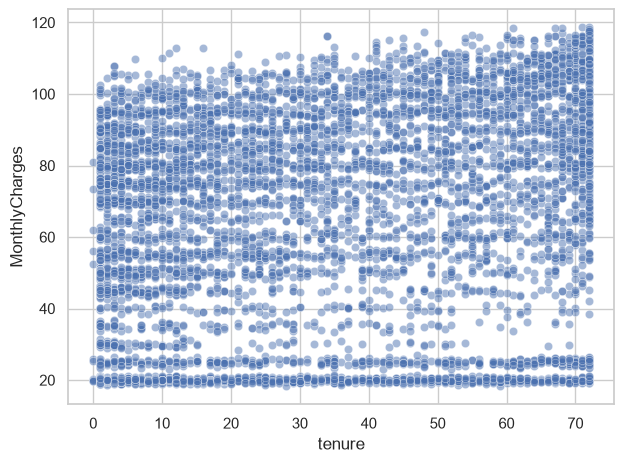

Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1307,166
Two year,1647,48


Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


In [13]:
def analyze_pair(data, col_a, col_b):
    if col_a not in data or col_b not in data:
        raise KeyError(f"Column not found. Available: {list(data.columns)}")
    a_num = pd.api.types.is_numeric_dtype(data[col_a])
    b_num = pd.api.types.is_numeric_dtype(data[col_b])
    if a_num and b_num:
        clean = data[[col_a, col_b]].dropna()
        print("Numerical vs numerical; Pearson:", clean[col_a].corr(clean[col_b]))
        sns.scatterplot(data=clean, x=col_a, y=col_b, alpha=.5); plt.tight_layout(); plt.show()
    elif a_num != b_num:
        num, cat = (col_a, col_b) if a_num else (col_b, col_a)
        clean = data[[num, cat]].dropna()
        display(clean.groupby(cat)[num].agg(["count", "mean", "median", "std"]).round(3))
        sns.boxplot(data=clean, x=cat, y=num); plt.xticks(rotation=30, ha="right")
        plt.tight_layout(); plt.show()
    else:
        display(pd.crosstab(data[col_a], data[col_b]))
        display(pd.crosstab(data[col_a], data[col_b], normalize="index").mul(100).round(2))

# Examples:
analyze_pair(df, "tenure", "MonthlyCharges")
analyze_pair(df, "Contract", "Churn")

## Findings template and conclusion
For each pair, document the variable types, pattern, statistic or percentages, outliers/small groups, limitations, and potential feature-engineering use. Summarize the strongest relationships observed. Remember: relationship is not causation.